In [49]:
!pip install xgboost lightgbm catboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


| العمود              | معناه                                                                   |
| ------------------- | ----------------------------------------------------------------------- |
| `id`                | رقم تعريفي لكل شخص، **مش feature مفيدة للتنبؤ غالبًا**                  |
| `gender`            | نوع الشخص: Male / Female / Other                                        |
| `age`               | عمر الشخص بالسنين                                                       |
| `hypertension`      | هل عنده ضغط دم مرتفع؟ `1 = نعم`، `0 = لا`                               |
| `heart_disease`     | هل عنده مرض بالقلب؟ `1 = نعم`، `0 = لا`                                 |
| `ever_married`      | هل تزوج من قبل؟ Yes / No                                                |
| `work_type`         | نوع العمل: Private / Self-employed / Govt_job / children / Never_worked |
| `Residence_type`    | مكان السكن: Urban / Rural                                               |
| `avg_glucose_level` | **متوسط مستوى الجلوكوز في الدم**                                        |
| `bmi`               | **مؤشر كتلة الجسم** Body Mass Index                                     |
| `smoking_status`    | حالة التدخين: formerly smoked / never smoked / smokes / Unknown         |
| `stroke`            | **الـ Target**: هل الشخص أصيب بجلطة؟ `1 = نعم`، `0 = لا`                |
**bold text**

In [50]:
df = pd.read_csv('/content/healthcare-dataset-stroke-data.csv')

In [51]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [53]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [54]:
df.duplicated().sum()

np.int64(0)

In [55]:
df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


In [56]:
df[df['bmi']==97.6]

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
2128,56420,Male,17.0,1,0,No,Private,Rural,61.67,97.6,Unknown,0


In [57]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values = np.nan,strategy='median')

df['bmi']=imputer.fit_transform(df[['bmi']])

In [58]:
df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0


In [59]:
df.drop('id',axis=1,inplace=True)

<Axes: xlabel='stroke', ylabel='bmi'>

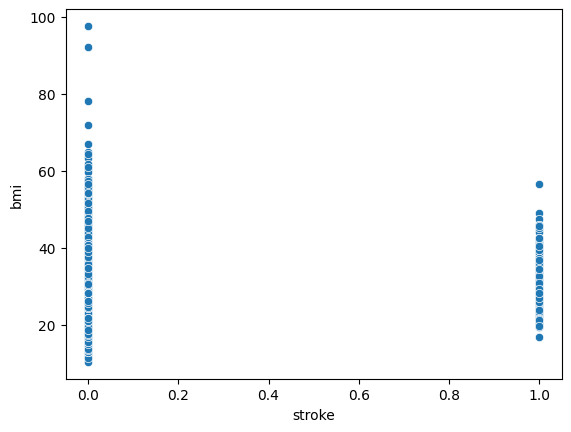

In [60]:
sns.scatterplot(data=df,x='stroke',y='bmi')

<Axes: xlabel='stroke', ylabel='avg_glucose_level'>

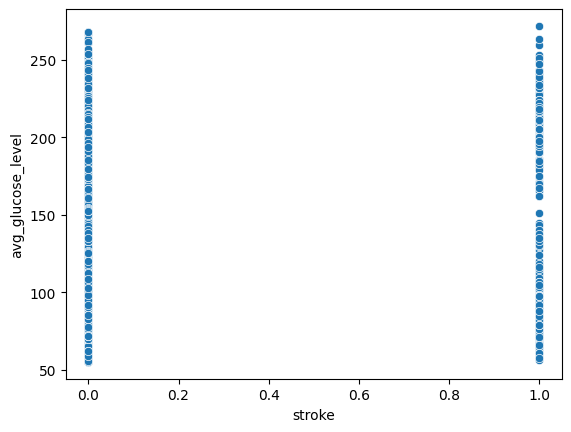

In [61]:
sns.scatterplot(data=df,x='stroke',y='avg_glucose_level')

<Axes: xlabel='smoking_status', ylabel='bmi'>

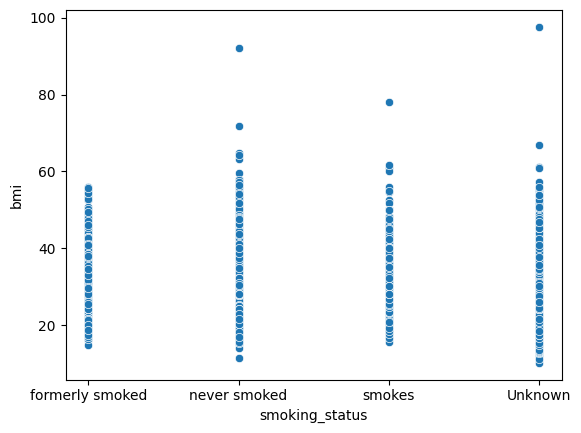

In [62]:
sns.scatterplot(data=df,x='smoking_status',y='bmi')

<Axes: xlabel='age', ylabel='bmi'>

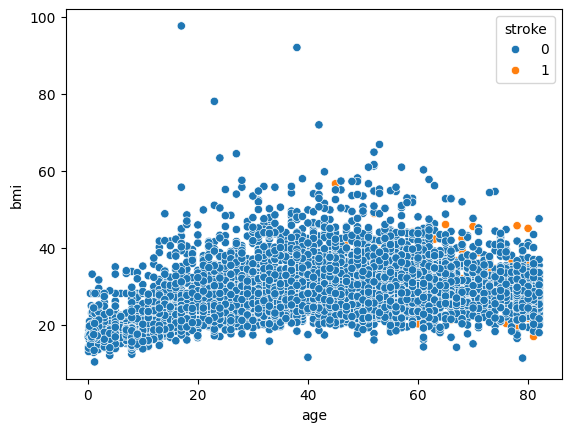

In [63]:
sns.scatterplot(data=df,x='age',y='bmi',hue='stroke')

In [64]:
df['stroke'].value_counts()

,count
stroke,
0,4861
1,249


In [65]:
for i in df.select_dtypes('object').columns:
  print(f'{i} number of unique = ',df[i].nunique())
  print('*'*40)

gender number of unique =  3
****************************************
ever_married number of unique =  2
****************************************
work_type number of unique =  5
****************************************
Residence_type number of unique =  2
****************************************
smoking_status number of unique =  4
****************************************


In [66]:
col = ['gender','ever_married','work_type','Residence_type','smoking_status']

In [67]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(handle_unknown='ignore')
for i in col:
  ohe_encoded = ohe.fit_transform(df[[i]]).toarray()
  ohe_df = pd.DataFrame(ohe_encoded,columns=ohe.get_feature_names_out([i]),index=df.index)
  df=pd.concat([df,ohe_df],axis=1)
  df.drop(i,axis=1,inplace=True)

In [68]:
print(ohe.categories_[0])

['Unknown' 'formerly smoked' 'never smoked' 'smokes']


In [69]:
df.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1,61.0,0,0,202.21,28.1,1,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,80.0,0,1,105.92,32.5,1,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,49.0,0,0,171.23,34.4,1,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,79.0,1,0,174.12,24.0,1,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [70]:
df.shape

(5110, 22)

In [71]:
from numpy._core.defchararray import upper
for i in df.columns:
  y = df[i]

  Q1 = y.quantile(0.25)
  Q3 = y.quantile(0.75)

  IQR = Q3-Q1

  lower = Q1-1.5*IQR
  upper = Q3+1.5*IQR

  outliers = y[(y<lower) | (y>upper)]

In [72]:
len(outliers)

789

In [73]:
print(outliers)

3       1.0
11      1.0
12      1.0
16      1.0
17      1.0
       ... 
5082    1.0
5084    1.0
5090    1.0
5093    1.0
5099    1.0
Name: smoking_status_smokes, Length: 789, dtype: float64


In [74]:
X = df.drop('stroke',axis=1)
y = df['stroke']

In [75]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=None)

In [76]:
num_cols = [
    'age',
    'hypertension',
    'heart_disease',
    'avg_glucose_level',
    'bmi'
]

In [77]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()

X_train[num_cols] = sc.fit_transform(X_train[num_cols])
X_test[num_cols] = sc.transform(X_test[num_cols])

In [78]:
from sklearn.linear_model import LogisticRegression
models = {'LogisticRegression': LogisticRegression(max_iter=200)}

In [79]:
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


[[960   0]
 [ 62   0]]


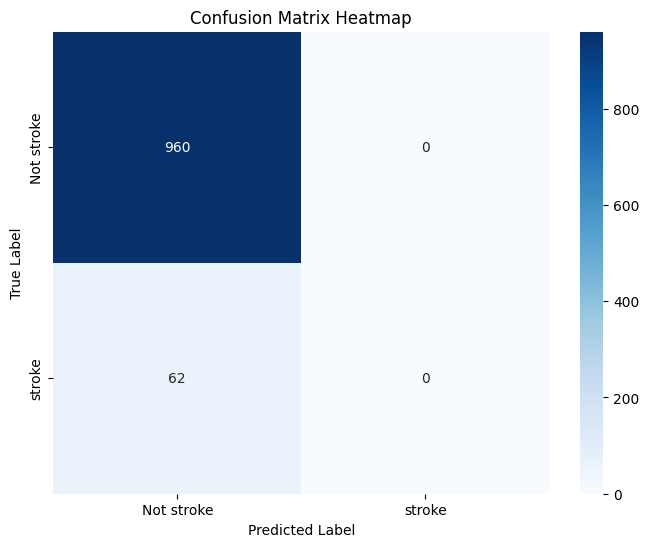

              precision    recall  f1-score   support

           0       0.94      1.00      0.97       960
           1       0.00      0.00      0.00        62

    accuracy                           0.94      1022
   macro avg       0.47      0.50      0.48      1022
weighted avg       0.88      0.94      0.91      1022



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [80]:
accuracy=[]
for model_name , model in models.items():
    model.fit(X_train,y_train)
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    Acc_Train = accuracy_score(y_train,y_pred_train)
    Acc_Test  =  accuracy_score(y_test,y_pred_test)


    Pre_Train = precision_score(y_train,y_pred_train)
    Pre_Test  =  precision_score(y_test,y_pred_test)

    Rec_Train = recall_score(y_train,y_pred_train)
    Rec_Test  =  recall_score(y_test,y_pred_test)

    F1_Train = f1_score(y_train,y_pred_train)
    F1_Test  =  f1_score(y_test,y_pred_test)

    accuracy.append([Acc_Train,Pre_Train,Rec_Train,F1_Train,Acc_Test,Pre_Test,Rec_Test,F1_Test])
    class_names=['Not stroke','stroke']
    cm = confusion_matrix(y_test,y_pred_test)
    print(cm)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names,
                yticklabels=class_names)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Confusion Matrix Heatmap')
    plt.show()
    print(classification_report(y_test,y_pred_test))

In [81]:
pd.DataFrame(accuracy,columns=["Acc_Train","Pre_Train","Rec_Train","F1_Train",
                               "Acc_Test","Pre_Test","Rec_Test","F1_Test"],index=models.keys())

,Acc_Train,Pre_Train,Rec_Train,F1_Train,Acc_Test,Pre_Test,Rec_Test,F1_Test
LogisticRegression,0.954501,1.0,0.005348,0.010638,0.939335,0.0,0.0,0.0


In [82]:
model = LogisticRegression()

In [83]:
model.fit(X_train, y_train)

LogisticRegression()

In [84]:
y_pred=model.predict(X_test)


In [85]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,\
confusion_matrix,classification_report,balanced_accuracy_score,roc_auc_score,roc_curve

In [86]:
accuracy_score(y_test,y_pred)

0.9393346379647749

In [87]:
precision_score(y_test,y_pred)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


0.0

In [88]:
recall_score(y_test,y_pred)

0.0

In [89]:
f1_score(y_test,y_pred)

0.0

In [90]:
balanced_accuracy_score(y_test,y_pred)

np.float64(0.5)

In [91]:
confus_matrix = confusion_matrix(y_test,y_pred)
confus_matrix

array([[960,   0],
       [ 62,   0]])

<Axes: >

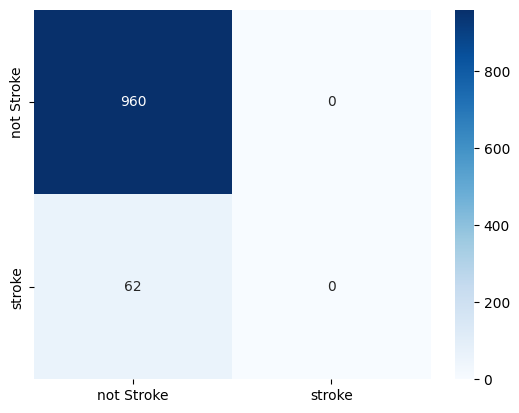

In [92]:
sns.heatmap(cm,annot=True,fmt="d",xticklabels=['not Stroke','stroke']
            ,yticklabels=['not Stroke','stroke'],cmap='Blues')

In [93]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.94      1.00      0.97       960
           1       0.00      0.00      0.00        62

    accuracy                           0.94      1022
   macro avg       0.47      0.50      0.48      1022
weighted avg       0.88      0.94      0.91      1022



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [94]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[960   0]
 [ 62   0]]


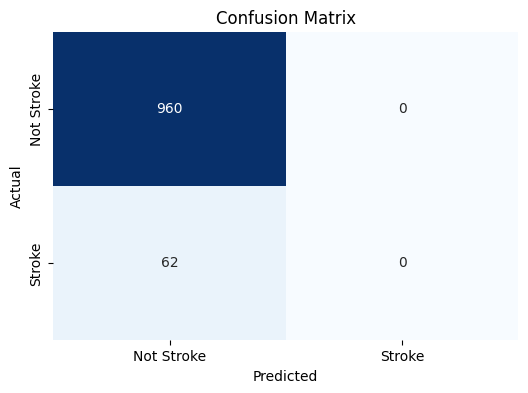


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      1.00      0.97       960
      Stroke       0.00      0.00      0.00        62

    accuracy                           0.94      1022
   macro avg       0.47      0.50      0.48      1022
weighted avg       0.88      0.94      0.91      1022

ROC-AUC: 0.8518145161290323


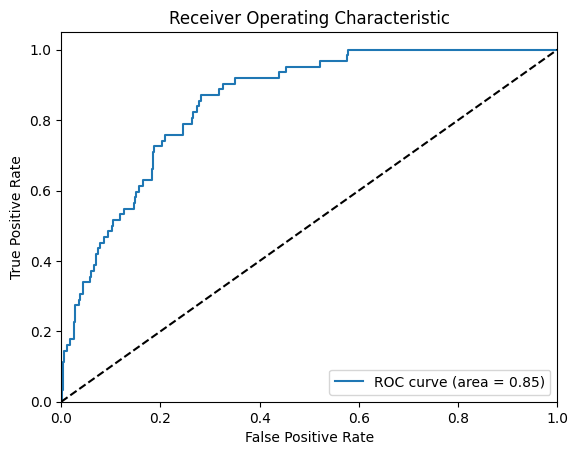

PR AUC: 0.28746116812108147


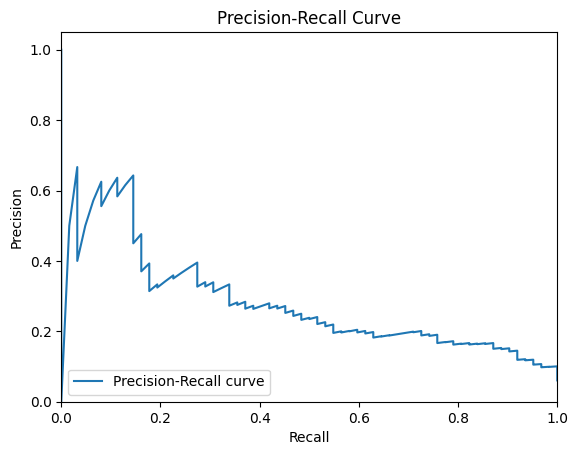

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
  8%|▊         | 1/13 [00:01<00:14,  1.17s/it]


Confusion Matrix:
 [[955   5]
 [ 62   0]]


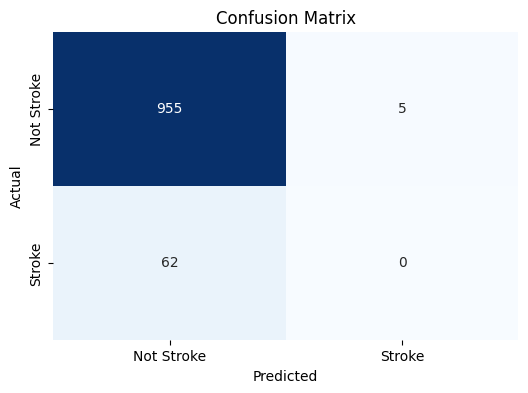


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      0.99      0.97       960
      Stroke       0.00      0.00      0.00        62

    accuracy                           0.93      1022
   macro avg       0.47      0.50      0.48      1022
weighted avg       0.88      0.93      0.91      1022

ROC-AUC: 0.6639364919354838


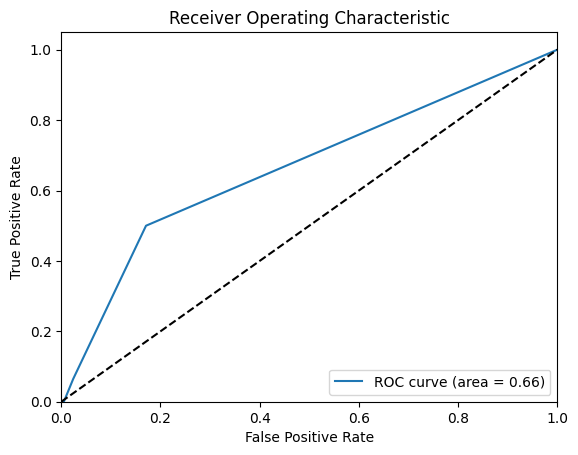

PR AUC: 0.10912139529019775


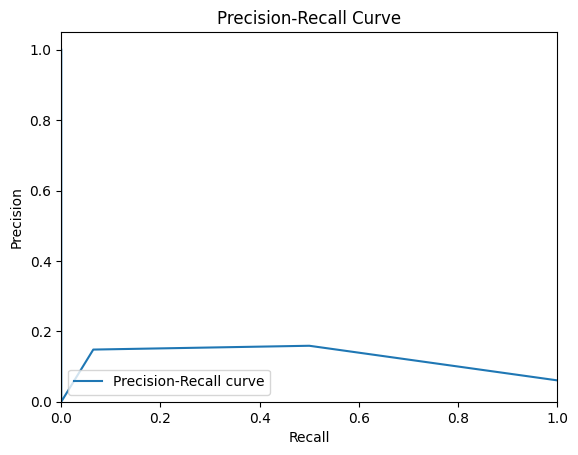

 15%|█▌        | 2/13 [00:02<00:15,  1.43s/it]


Confusion Matrix:
 [[960   0]
 [ 62   0]]


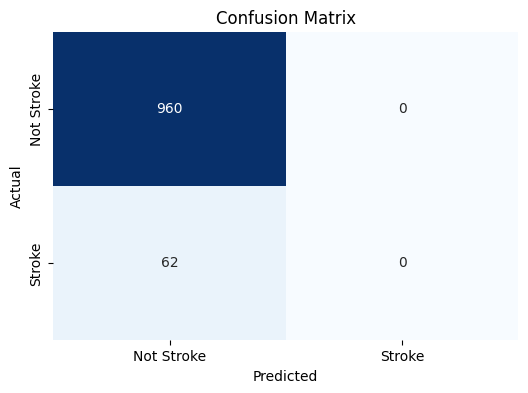


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      1.00      0.97       960
      Stroke       0.00      0.00      0.00        62

    accuracy                           0.94      1022
   macro avg       0.47      0.50      0.48      1022
weighted avg       0.88      0.94      0.91      1022

ROC-AUC: 0.608635752688172


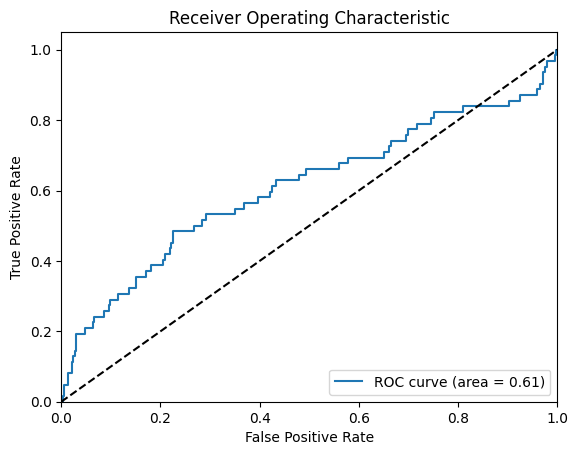

PR AUC: 0.1308778666929339


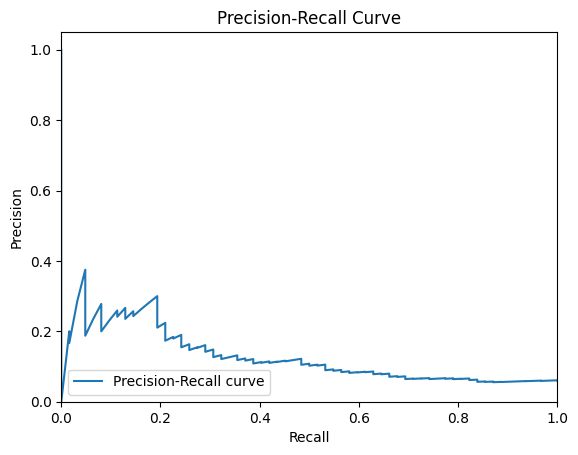

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
 23%|██▎       | 3/13 [00:10<00:43,  4.37s/it]


Confusion Matrix:
 [[922  38]
 [ 49  13]]


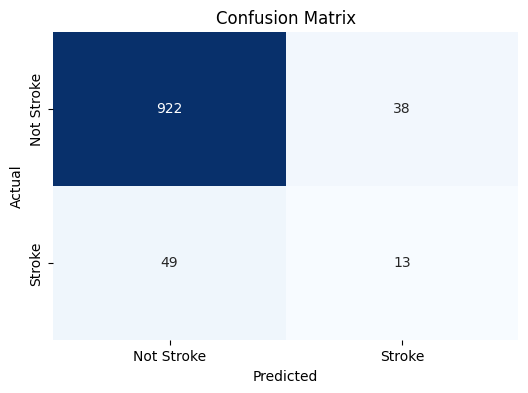


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.96      0.95       960
      Stroke       0.25      0.21      0.23        62

    accuracy                           0.91      1022
   macro avg       0.60      0.59      0.59      1022
weighted avg       0.91      0.91      0.91      1022

ROC-AUC: 0.5850470430107527


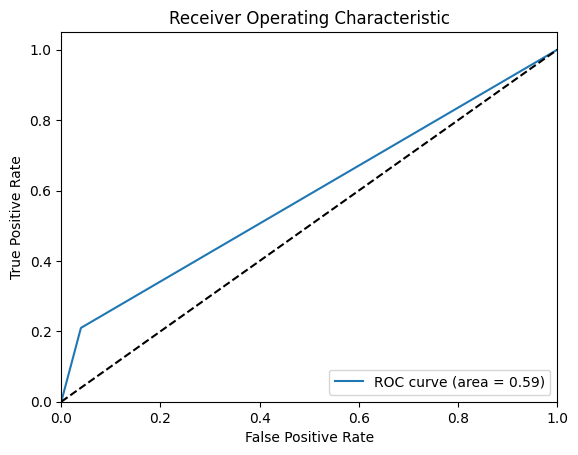

PR AUC: 0.10139239080519524


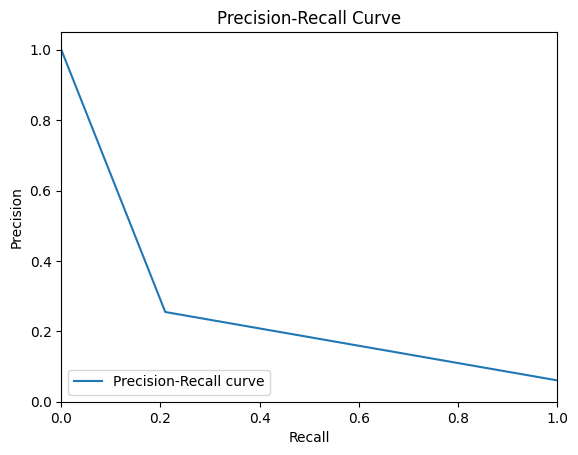

 31%|███       | 4/13 [00:12<00:28,  3.20s/it]


Confusion Matrix:
 [[323 637]
 [  0  62]]


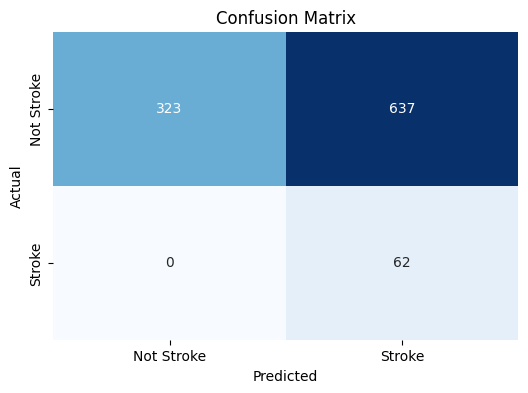


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      0.34      0.50       960
      Stroke       0.09      1.00      0.16        62

    accuracy                           0.38      1022
   macro avg       0.54      0.67      0.33      1022
weighted avg       0.94      0.38      0.48      1022

ROC-AUC: 0.827755376344086


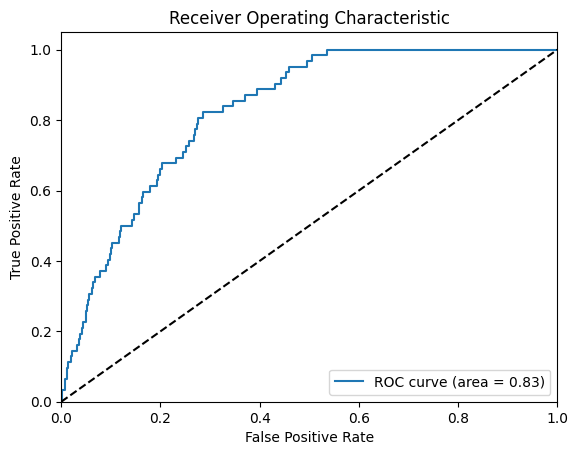

PR AUC: 0.21009153149304258


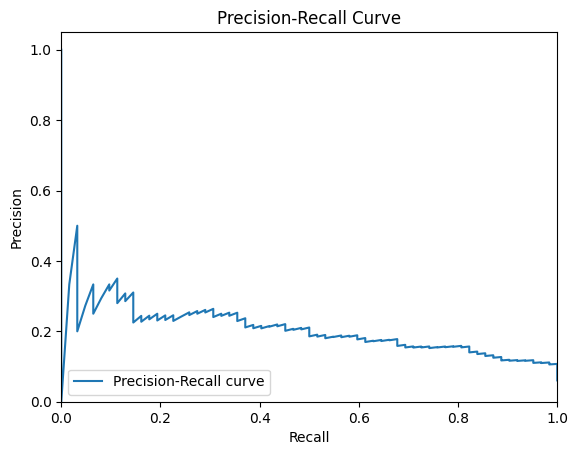

 38%|███▊      | 5/13 [00:13<00:19,  2.41s/it]


Confusion Matrix:
 [[960   0]
 [ 61   1]]


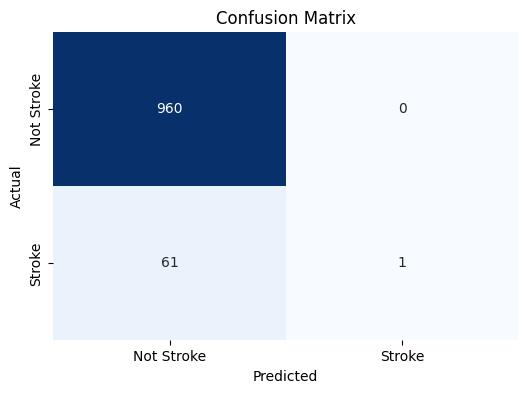


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      1.00      0.97       960
      Stroke       1.00      0.02      0.03        62

    accuracy                           0.94      1022
   macro avg       0.97      0.51      0.50      1022
weighted avg       0.94      0.94      0.91      1022

ROC-AUC: 0.8040238575268817


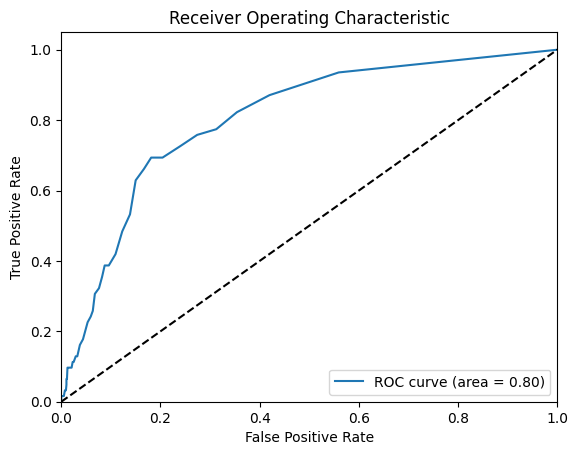

PR AUC: 0.19962352733625466


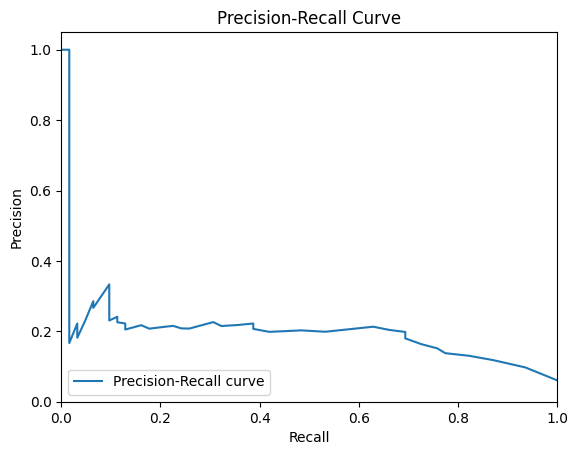

 46%|████▌     | 6/13 [00:15<00:16,  2.42s/it]


Confusion Matrix:
 [[952   8]
 [ 60   2]]


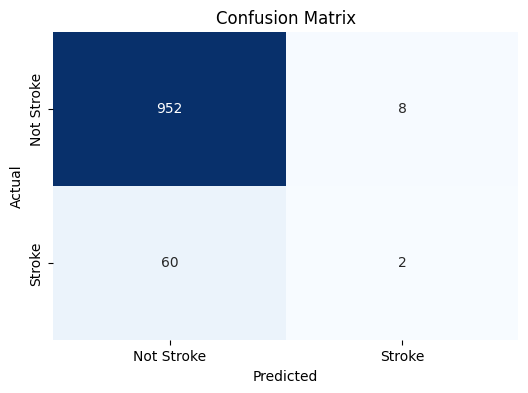


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      0.99      0.97       960
      Stroke       0.20      0.03      0.06        62

    accuracy                           0.93      1022
   macro avg       0.57      0.51      0.51      1022
weighted avg       0.90      0.93      0.91      1022

ROC-AUC: 0.7304099462365592


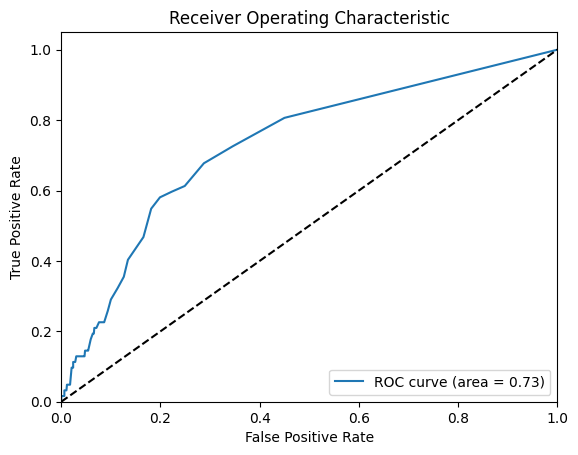

PR AUC: 0.15221584749517392


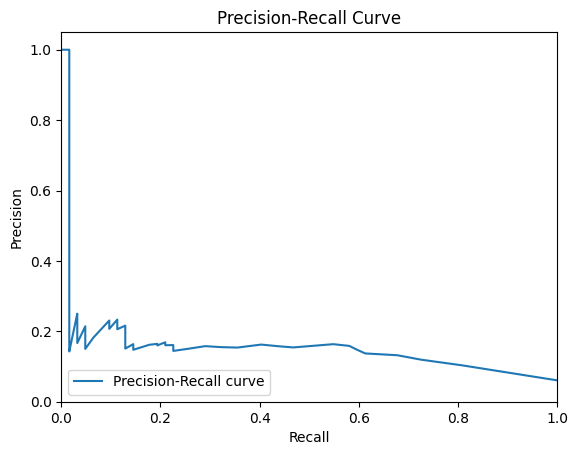

 54%|█████▍    | 7/13 [00:17<00:13,  2.31s/it]


Confusion Matrix:
 [[960   0]
 [ 62   0]]


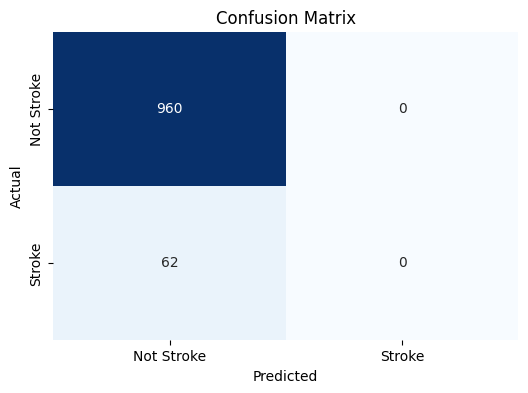


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      1.00      0.97       960
      Stroke       0.00      0.00      0.00        62

    accuracy                           0.94      1022
   macro avg       0.47      0.50      0.48      1022
weighted avg       0.88      0.94      0.91      1022

ROC-AUC: 0.8402217741935485


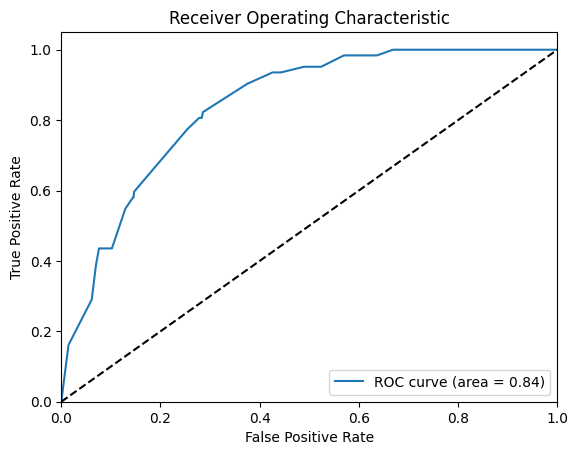

PR AUC: 0.22834136832582944


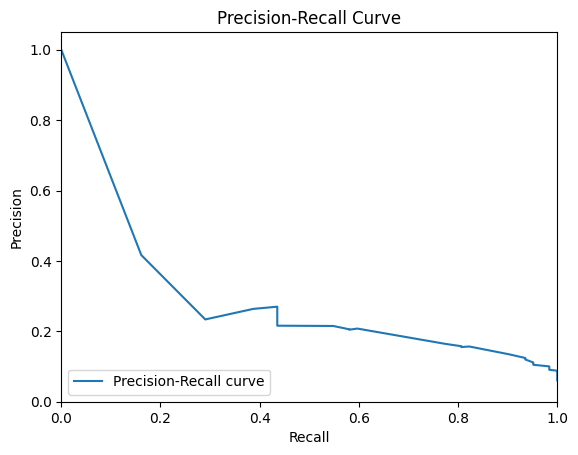

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
 62%|██████▏   | 8/13 [00:20<00:12,  2.53s/it]


Confusion Matrix:
 [[960   0]
 [ 61   1]]


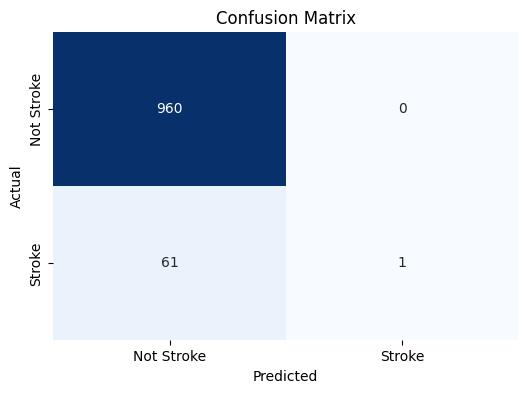


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      1.00      0.97       960
      Stroke       1.00      0.02      0.03        62

    accuracy                           0.94      1022
   macro avg       0.97      0.51      0.50      1022
weighted avg       0.94      0.94      0.91      1022

ROC-AUC: 0.8270329301075269


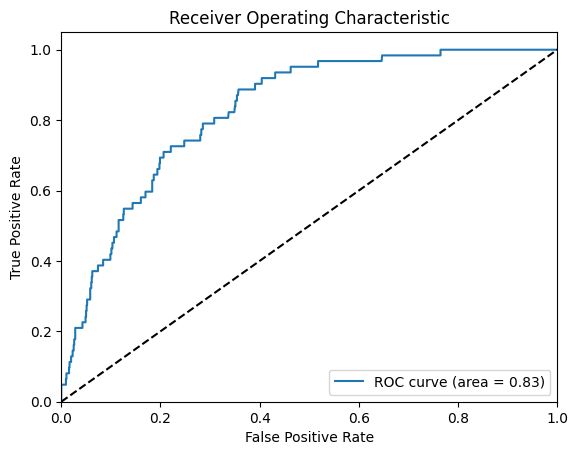

PR AUC: 0.24744261462748354


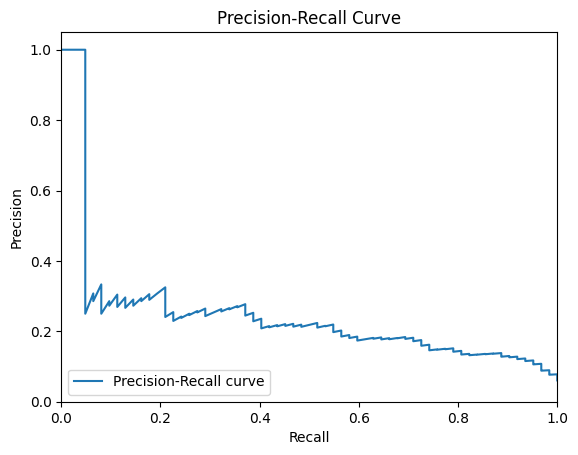

 69%|██████▉   | 9/13 [00:25<00:12,  3.24s/it]


Confusion Matrix:
 [[953   7]
 [ 57   5]]


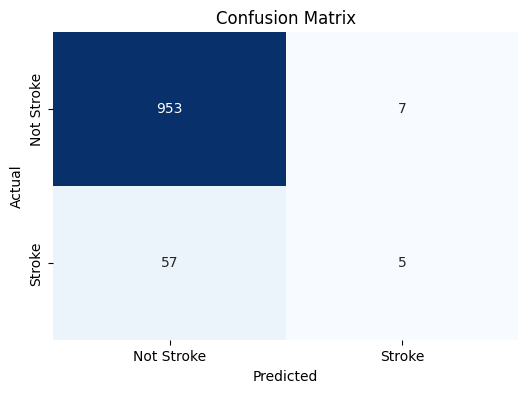


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      0.99      0.97       960
      Stroke       0.42      0.08      0.14        62

    accuracy                           0.94      1022
   macro avg       0.68      0.54      0.55      1022
weighted avg       0.91      0.94      0.92      1022

ROC-AUC: 0.8115087365591398


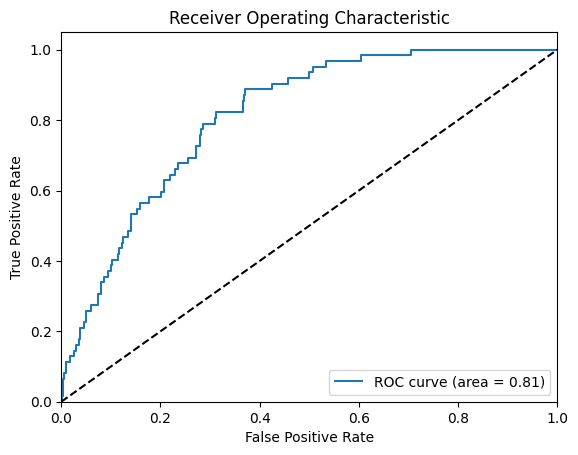

PR AUC: 0.21141661277465426


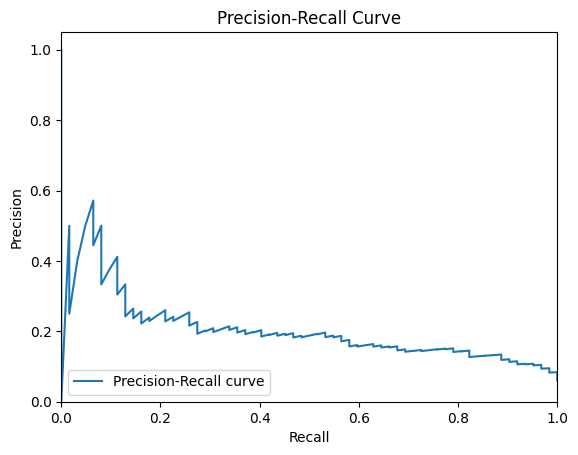

 77%|███████▋  | 10/13 [00:28<00:10,  3.35s/it]/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [15:53:19] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[952   8]
 [ 55   7]]


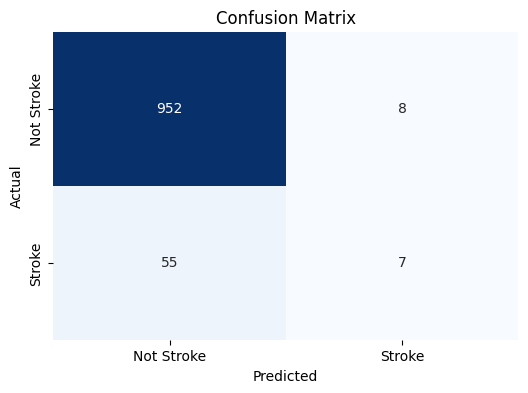


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       960
      Stroke       0.47      0.11      0.18        62

    accuracy                           0.94      1022
   macro avg       0.71      0.55      0.57      1022
weighted avg       0.92      0.94      0.92      1022

ROC-AUC: 0.7847950268817205


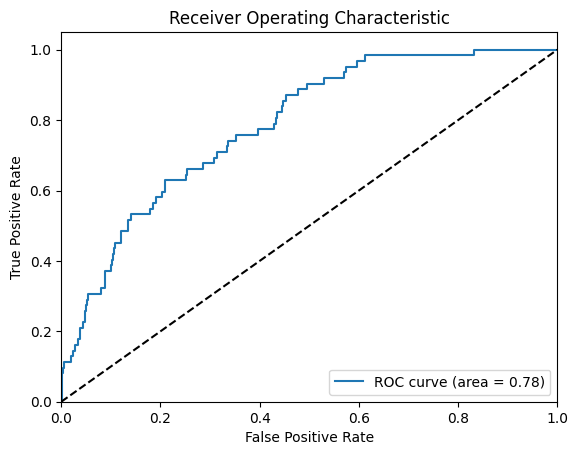

PR AUC: 0.2181458476837159


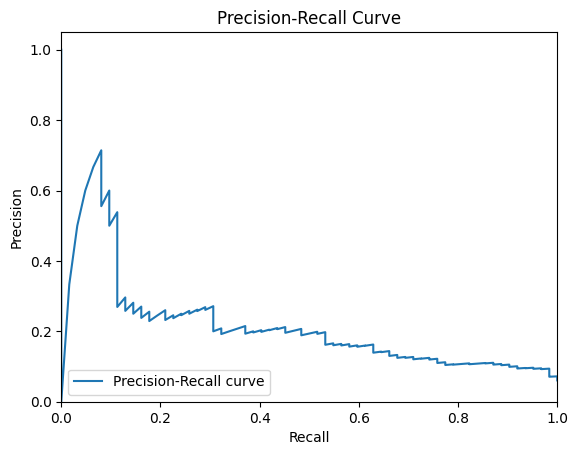

 85%|████████▍ | 11/13 [00:31<00:06,  3.17s/it]


Confusion Matrix:
 [[957   3]
 [ 61   1]]


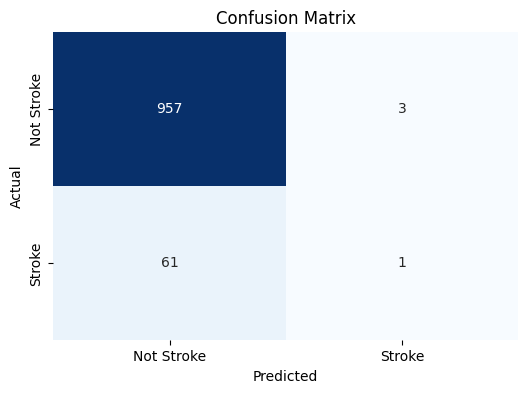


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      1.00      0.97       960
      Stroke       0.25      0.02      0.03        62

    accuracy                           0.94      1022
   macro avg       0.60      0.51      0.50      1022
weighted avg       0.90      0.94      0.91      1022

ROC-AUC: 0.8186323924731183


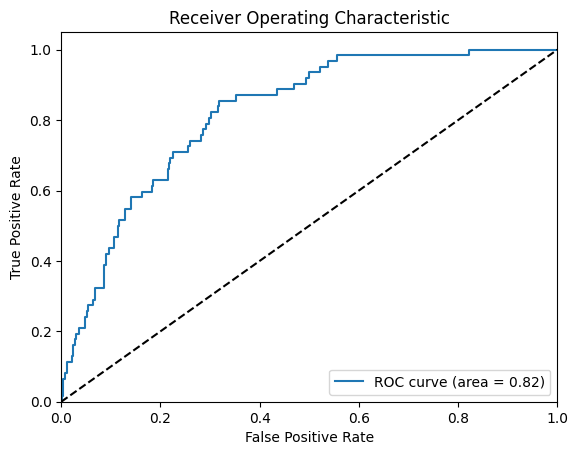

PR AUC: 0.21550093401238157


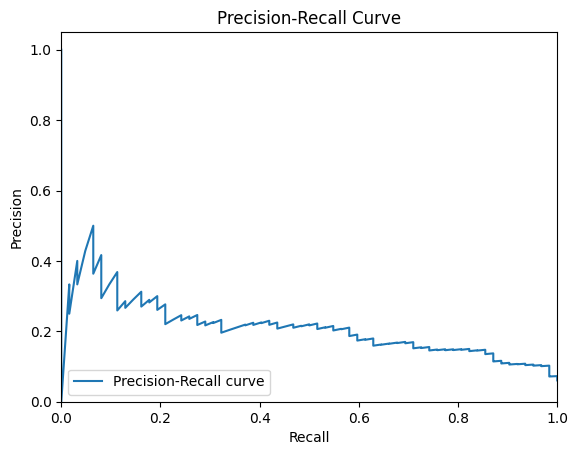

 92%|█████████▏| 12/13 [00:43<00:05,  5.70s/it]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 187, number of negative: 3901
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001357 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 647
[LightGBM] [Info] Number of data points in the train set: 4088, number of used features: 20
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.045744 -> initscore=-3.037880
[LightGBM] [Info] Start training from score -3.037880

Confusion Matrix:
 [[953   7]
 [ 56   6]]


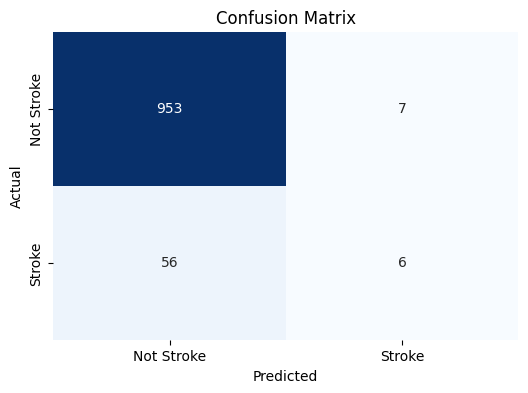


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      0.99      0.97       960
      Stroke       0.46      0.10      0.16        62

    accuracy                           0.94      1022
   macro avg       0.70      0.54      0.56      1022
weighted avg       0.92      0.94      0.92      1022

ROC-AUC: 0.8016633064516129


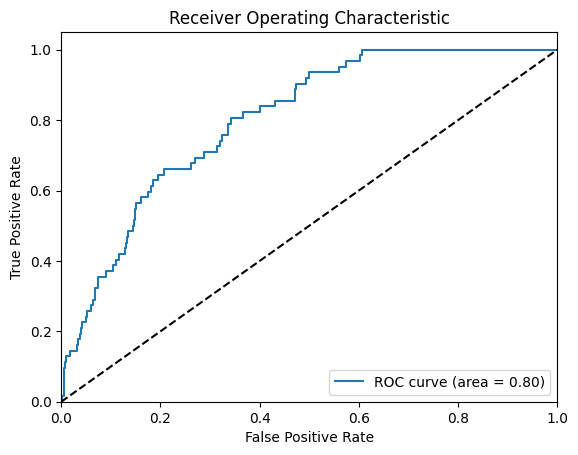

PR AUC: 0.20869361544284903


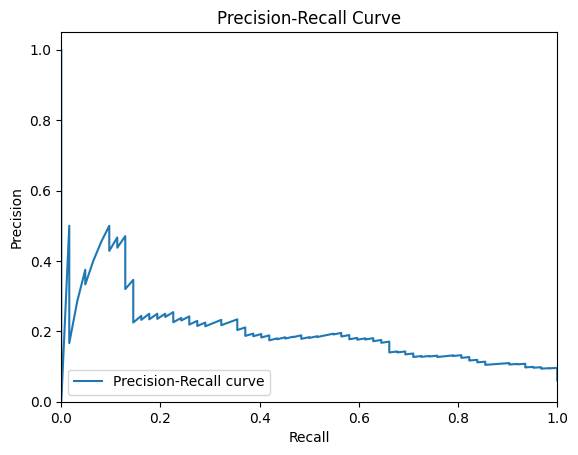

100%|██████████| 13/13 [00:44<00:00,  3.42s/it]


In [95]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [15:53:35] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[952   8]
 [ 57   5]]


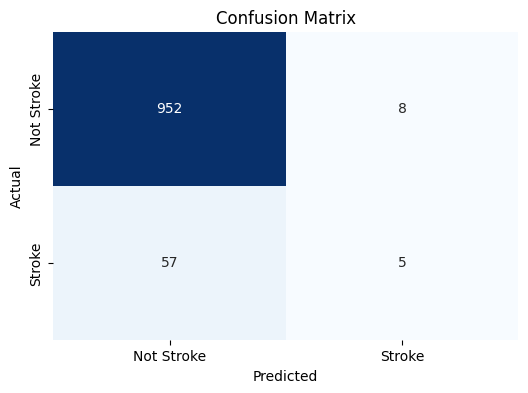


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      0.99      0.97       960
      Stroke       0.38      0.08      0.13        62

    accuracy                           0.94      1022
   macro avg       0.66      0.54      0.55      1022
weighted avg       0.91      0.94      0.92      1022

ROC-AUC: 0.8543346774193548


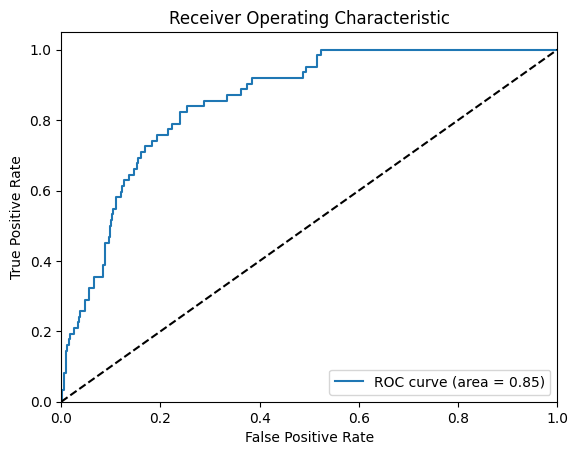

PR AUC: 0.2649542233435514


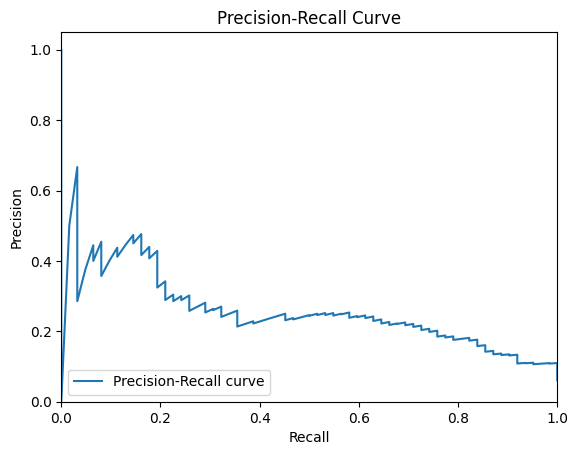

In [96]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(X_train, y_train)
voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = voting_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred),
    "Test Precision": precision_score(y_test, voting_test_pred),
    "Train Recall": recall_score(y_train, voting_train_pred),
    "Test Recall": recall_score(y_test, voting_test_pred),
    "Train F1 Score": f1_score(y_train, voting_train_pred),
    "Test F1 Score": f1_score(y_test, voting_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [15:53:50] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "max_iter" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[947  13]
 [ 60   2]]


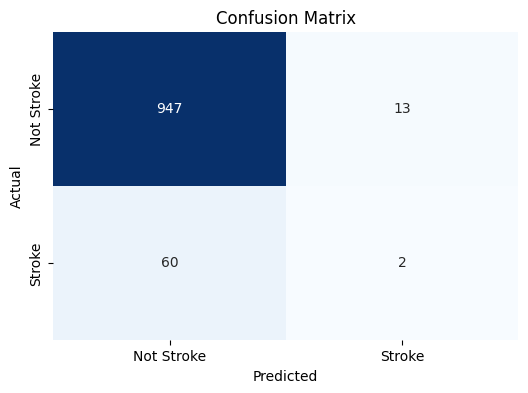


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      0.99      0.96       960
      Stroke       0.13      0.03      0.05        62

    accuracy                           0.93      1022
   macro avg       0.54      0.51      0.51      1022
weighted avg       0.89      0.93      0.91      1022

ROC-AUC: 0.7848790322580645


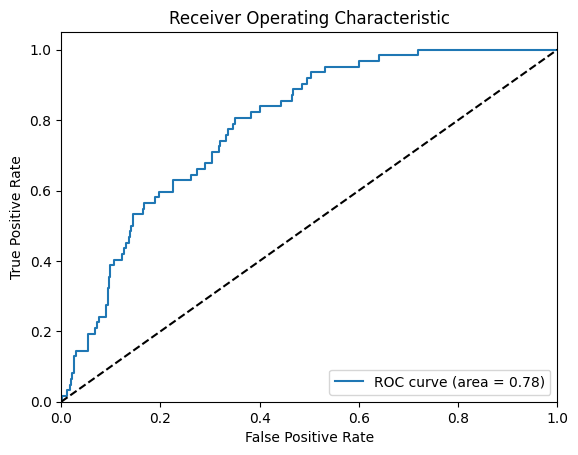

PR AUC: 0.1599071202726609


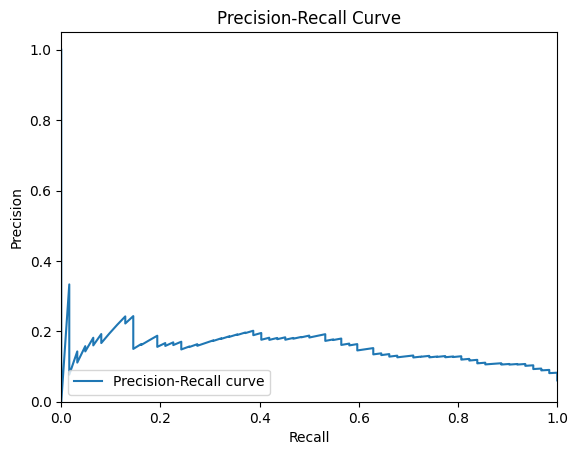

In [97]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),


    ],
    final_estimator=XGBClassifier(max_iter=2000),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(X_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train)
stack_auto_test_pred  = stack_auto.predict(X_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [98]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)

In [99]:
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Decision Tree,1.000000,0.914873,1.000000,0.254902,1.000000,0.209677,1.000000,0.230088,1.000000,0.585047,0.585047,0.101392
XGBoost,0.999266,0.938356,1.000000,0.466667,0.983957,0.112903,0.991914,0.181818,0.991979,0.552285,0.784795,0.218146
Naive Bayes,0.360078,0.376712,0.065474,0.088698,0.978610,1.000000,0.122736,0.162943,0.654519,0.668229,0.827755,0.210092
LightGBM,0.995108,0.938356,0.988304,0.461538,0.903743,0.096774,0.944134,0.160000,0.951615,0.544741,0.801663,0.208694
Hist Gradient Boosting,0.994618,0.937378,0.994012,0.416667,0.887701,0.080645,0.937853,0.135135,0.943722,0.536677,0.811509,0.211417
Voting Classifier,0.998532,0.936399,0.994536,0.384615,0.973262,0.080645,0.983784,0.133333,0.986503,0.536156,0.854335,0.264954
Extra Trees,1.000000,0.933464,1.000000,0.200000,1.000000,0.032258,1.000000,0.055556,1.000000,0.511962,0.730410,0.152216
Stacking Classifier,0.944227,0.928571,0.140351,0.133333,0.042781,0.032258,0.065574,0.051948,0.515110,0.509358,0.784879,0.159907
Gradient Boosting,0.961350,0.940313,1.000000,1.000000,0.155080,0.016129,0.268519,0.031746,0.577540,0.508065,0.827033,0.247443
Random Forest,1.000000,0.940313,1.000000,1.000000,1.000000,0.016129,1.000000,0.031746,1.000000,0.508065,0.804024,0.199624


<Axes: >

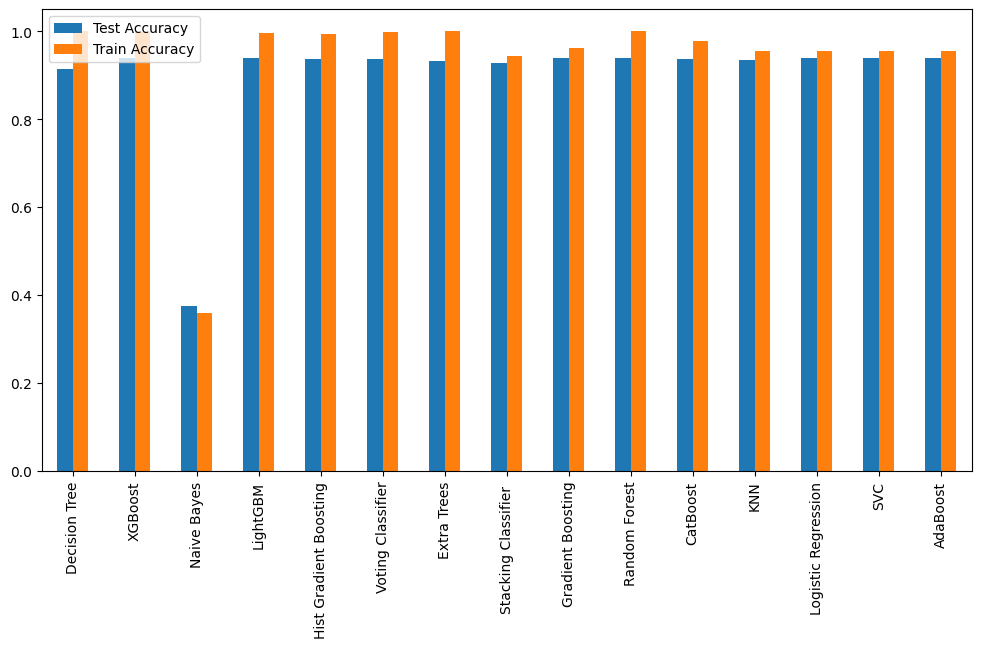

In [100]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

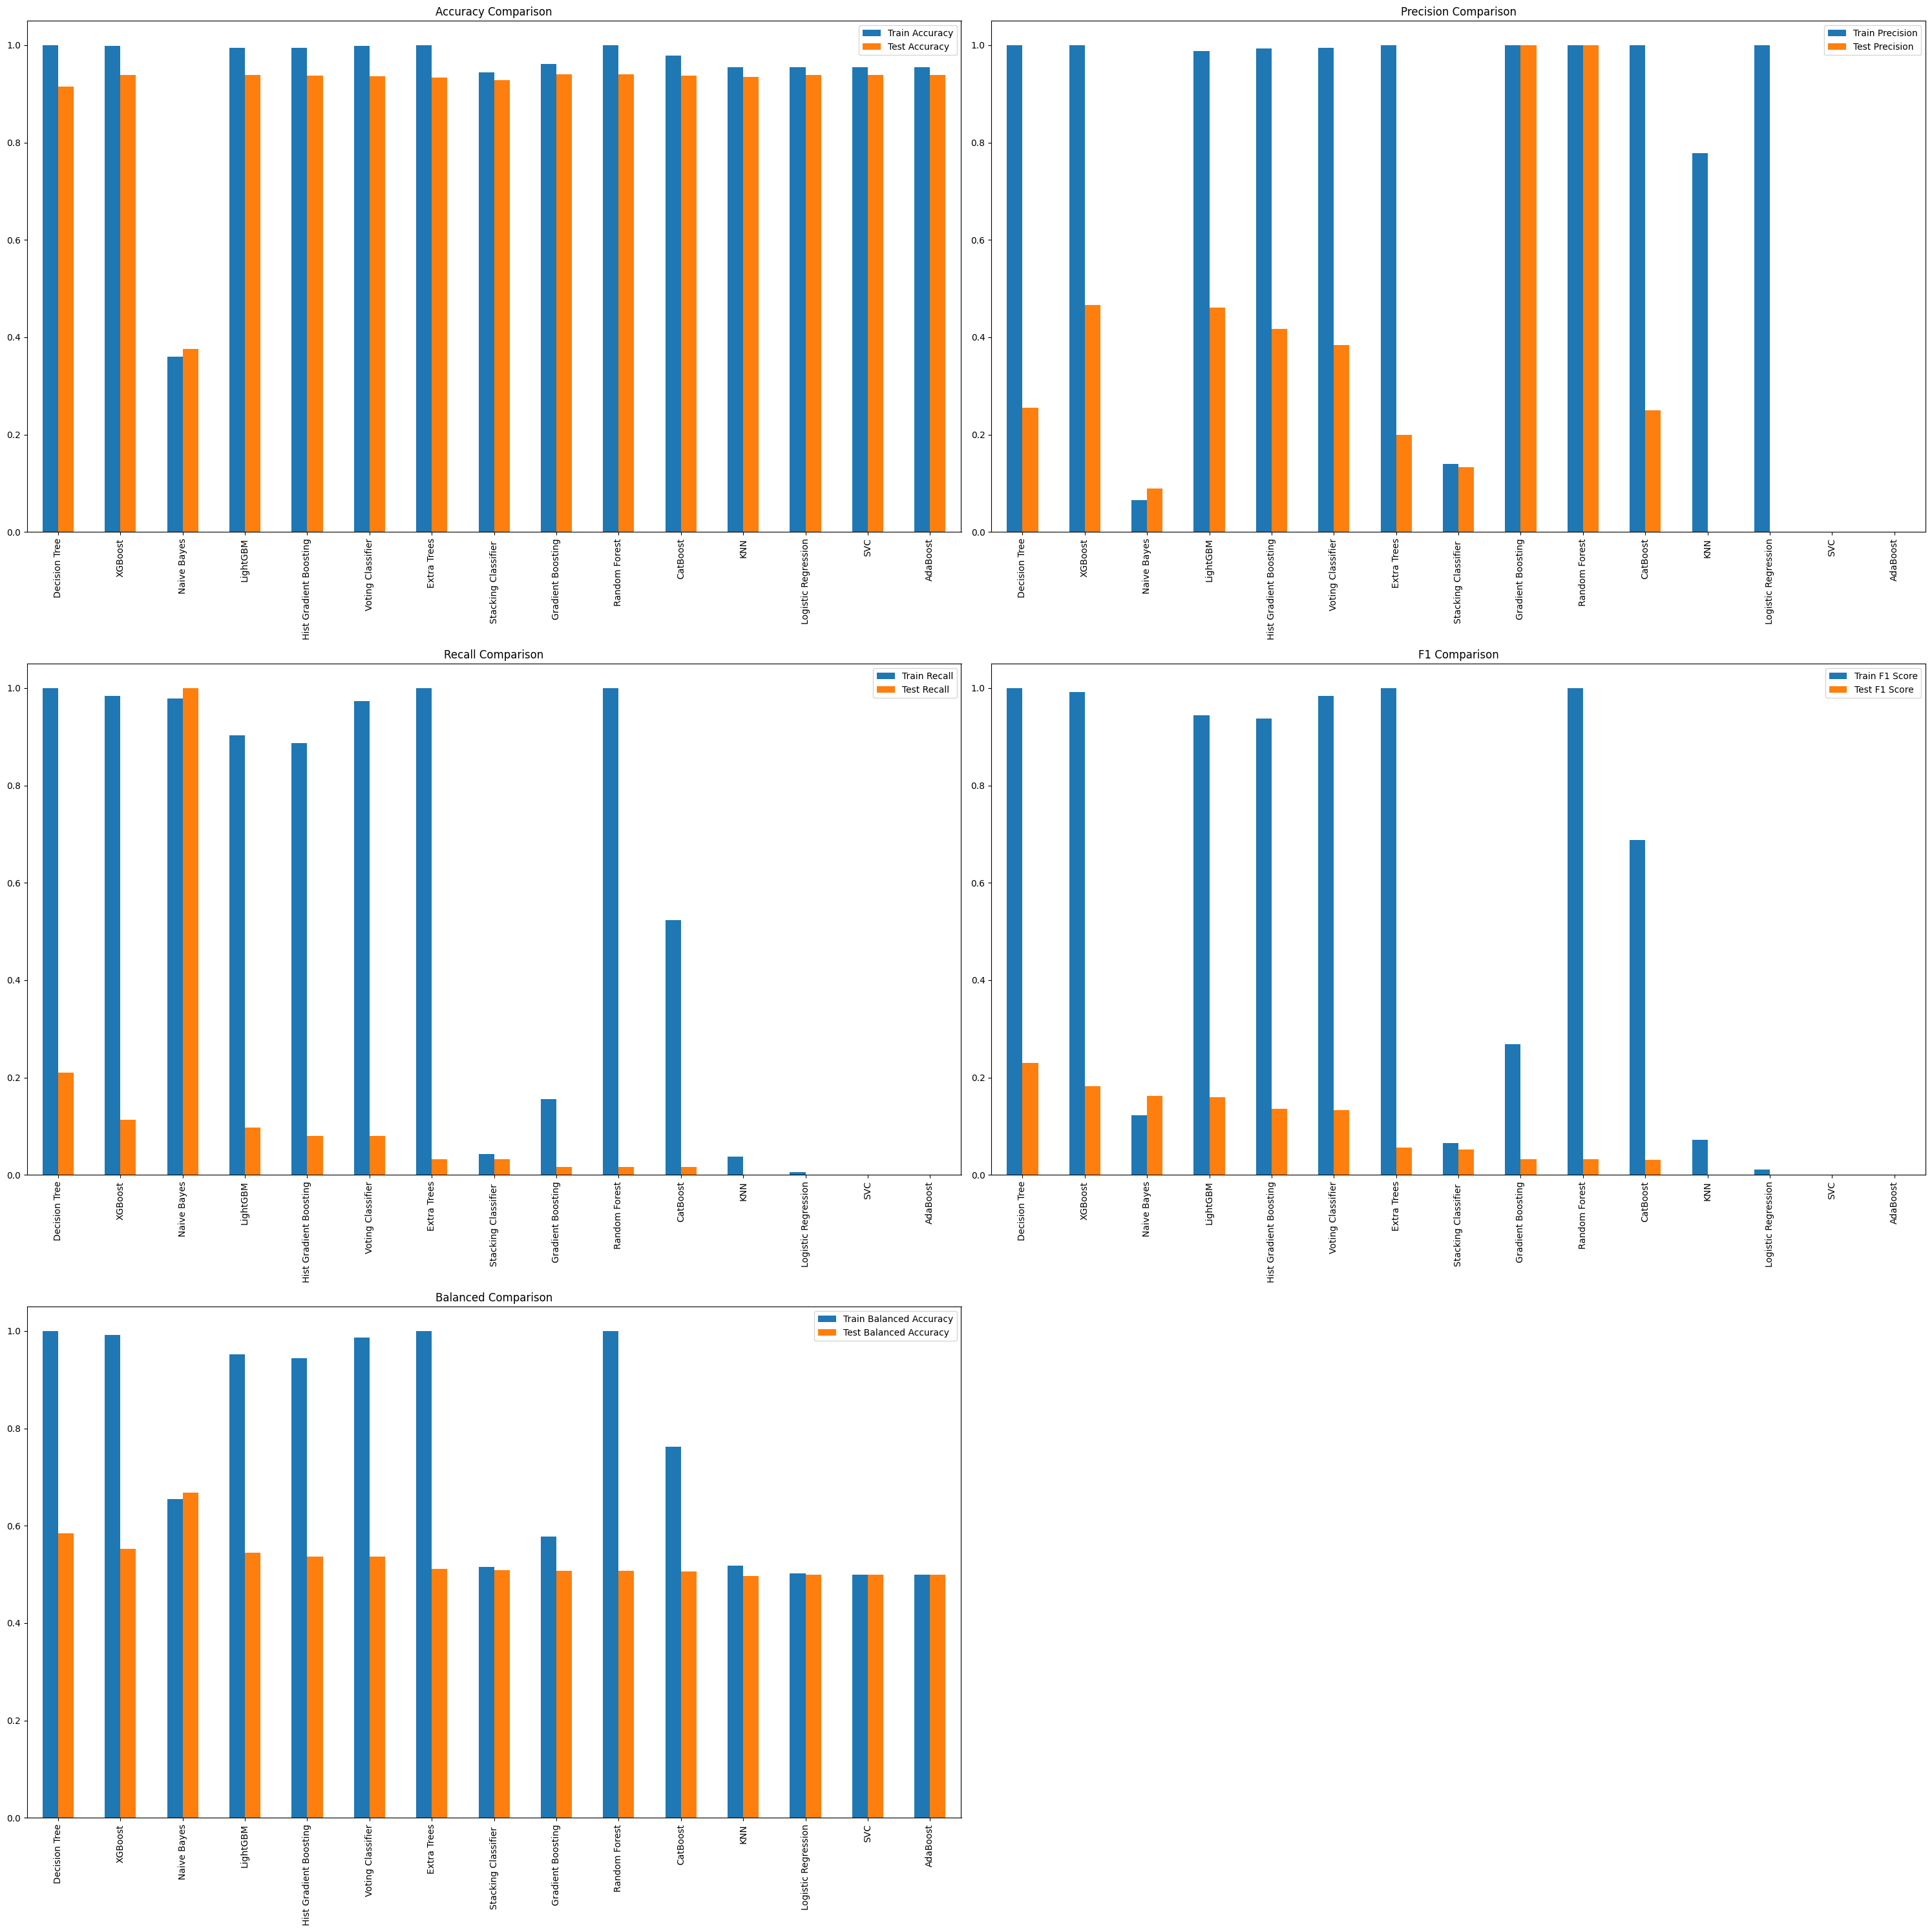

In [101]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()